# Trial 6 — Three Architectures: ConvLSTM, PredRNN-V2, VideoTransformer

**What changed from Trial 5:**

**New architectures:**
1. **PredRNN-V2** — ST-LSTM cells with spatiotemporal memory flow (memory flows both across time AND between layers, fixing ConvLSTM's horizontal-only memory). Includes Causal-LSTM-style gradient flow on the top layer.
2. **VideoTransformer** — Factorized space-time attention (TimeSformer-style). Each frame is patched into 25 tokens (19×19 patches over 95×95). Spatial attention within frame, then temporal attention across frames per spatial position.
3. **ConvLSTM** kept as baseline (Trial 5 winner) for direct comparison.

**Everything else from Trial 5 is unchanged:**
- 5-channel multi-channel input (raw, d1, d5, roll_mean, roll_std)
- 4-term combined loss (MSE, Pearson, magnitude-masked directional, trajectory)
- Cosine annealing T_0=20, PATIENCE=15
- Inverse-MSE weighted ensemble (now across 3 models)

**Output prefix:** `trial6_*`. No files need deleting.

In [1]:
# Cell 1 – Imports & Configuration
import os, time, copy, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# ── Paths ─────────────────────────────────────────────────────────────────────
_cwd        = os.getcwd()
PROJECT_DIR = os.path.abspath(os.path.join(_cwd, '..')) \
              if os.path.basename(_cwd) == 'notebooks' else _cwd
DATA_DIR    = os.path.join(PROJECT_DIR, 'data', 'processed')
MODELS_DIR  = os.path.join(PROJECT_DIR, 'models')
PREDS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'predictions')
PLOTS_DIR   = os.path.join(PROJECT_DIR, 'outputs', 'plots')

# ── Hyperparameters ───────────────────────────────────────────────────────────
N_STOCKS    = 95
LOOKBACK    = 20
HORIZON     = 5
TRAIN_RATIO = 0.70

# Multi-channel input (same as Trial 5)
N_CHANNELS  = 5
DELTA_SHORT = 1
DELTA_LONG  = 5
ROLLING_WIN = 4

BATCH_SIZE   = 16
LR           = 1e-3
MAX_EPOCHS   = 60
WEIGHT_DECAY = 1e-4

T_0      = 20
T_MULT   = 2
ETA_MIN  = 1e-6
PATIENCE = 15

ALPHA = 0.35
BETA  = 0.25
GAMMA = 0.30
DELTA = 0.10
DIR_MAG_THRESH = 0.005

# PredRNN config
PREDRNN_LAYERS = 4
PREDRNN_HID    = 32
PREDRNN_SP     = 24

# Transformer config
TX_PATCH_SIZE  = 19          # 95 / 19 = 5  -> 25 spatial tokens per frame
TX_EMBED_DIM   = 128
TX_HEADS       = 4
TX_SP_LAYERS   = 4
TX_TP_LAYERS   = 2

device  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PIN_MEM = device.type == 'cuda'

print(f'Device      : {device}')
print(f'PyTorch     : {torch.__version__}')
print(f'Channels/px : {N_CHANNELS}')
print(f'Models      : ConvLSTM, PredRNN-V2, VideoTransformer')
print(f'Scheduler   : CosineAnnealingWarmRestarts  T_0={T_0}  T_mult={T_MULT}')
print(f'Patience    : {PATIENCE} epochs')
print(f'Loss        : a={ALPHA} MSE | b={BETA} Pearson | g={GAMMA} Dir(mask>{DIR_MAG_THRESH}) | d={DELTA} Traj')


Device      : cuda
PyTorch     : 2.6.0+cu124
Channels/px : 5
Models      : ConvLSTM, PredRNN-V2, VideoTransformer
Scheduler   : CosineAnnealingWarmRestarts  T_0=20  T_mult=2
Patience    : 15 epochs
Loss        : a=0.35 MSE | b=0.25 Pearson | g=0.3 Dir(mask>0.005) | d=0.1 Traj


In [2]:
# Cell 2 – Load Processed Data
corr_video  = np.load(os.path.join(DATA_DIR, 'corr_video.npy'))
fiedler_ord = np.load(os.path.join(DATA_DIR, 'fiedler_order.npy'))
snap_ts     = np.load(os.path.join(DATA_DIR, 'snap_timesteps.npy'), allow_pickle=True)
with open(os.path.join(DATA_DIR, 'pair_meta.pkl'), 'rb') as f:
    pair_meta = pickle.load(f)
with open(os.path.join(DATA_DIR, 'video_meta.pkl'), 'rb') as f:
    video_meta = pickle.load(f)
tickers = pair_meta['tickers']
N_SNAPS = corr_video.shape[0]

print(f'corr_video  : {corr_video.shape}  dtype={corr_video.dtype}')
print(f'N stocks    : {len(tickers)}')
print(f'N snapshots : {N_SNAPS}')


corr_video  : (1157, 95, 95)  dtype=float32
N stocks    : 95
N snapshots : 1157


In [3]:
# Cell 3 – Build Multi-Channel Video (same as Trial 5)

def build_multichannel_video(corr_video, delta_short=1, delta_long=5, win=4):
    T, H, W = corr_video.shape
    out = np.zeros((T, 5, H, W), dtype=np.float32)
    out[:, 0] = corr_video
    out[delta_short:, 1] = corr_video[delta_short:] - corr_video[:-delta_short]
    out[delta_long:,  2] = corr_video[delta_long:]  - corr_video[:-delta_long]
    cum, cum2 = np.cumsum(corr_video, 0), np.cumsum(corr_video**2, 0)
    for t in range(T):
        lo = max(0, t - win + 1)
        n  = t - lo + 1
        s  = cum[t]  - (cum[lo-1]  if lo > 0 else 0.0)
        s2 = cum2[t] - (cum2[lo-1] if lo > 0 else 0.0)
        mean = s / n
        var  = np.maximum(0.0, s2 / n - mean**2)
        out[t, 3] = mean
        out[t, 4] = np.sqrt(var)
    return out

multichannel_video = build_multichannel_video(
    corr_video, DELTA_SHORT, DELTA_LONG, ROLLING_WIN
)
print(f'multichannel_video : {multichannel_video.shape}  ~{multichannel_video.nbytes / 1e6:.0f} MB')


multichannel_video : (1157, 5, 95, 95)  ~209 MB


In [4]:
# Cell 4 – Stratified Split, Dataset, DataLoaders

n_valid   = N_SNAPS - HORIZON
frame_mse = np.array([
    float(np.mean((corr_video[t] - corr_video[t + HORIZON]) ** 2))
    for t in range(n_valid)
], dtype=np.float32)

volatility_threshold = float(np.median(frame_mse))
valid_snaps = np.array([s for s in range(n_valid) if s >= LOOKBACK])
snap_v      = frame_mse[valid_snaps]
volatile_snaps = valid_snaps[snap_v >= volatility_threshold]
stable_snaps   = valid_snaps[snap_v <  volatility_threshold]

np.random.seed(42)
vol_train = np.random.choice(volatile_snaps, int(len(volatile_snaps) * TRAIN_RATIO), replace=False)
vol_val   = np.setdiff1d(volatile_snaps, vol_train)
sta_train = np.random.choice(stable_snaps,  int(len(stable_snaps)  * TRAIN_RATIO), replace=False)
sta_val   = np.setdiff1d(stable_snaps, sta_train)

train_snaps = np.sort(np.concatenate([vol_train, sta_train]))
val_snaps   = np.sort(np.concatenate([vol_val,   sta_val]))

print(f'Train: {len(train_snaps)}  Val: {len(val_snaps)}')

persistence_mse  = float(np.mean([
    np.mean((corr_video[s] - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
mean_train_frame = corr_video[train_snaps].mean(axis=0)
mean_frame_mse   = float(np.mean([
    np.mean((mean_train_frame - corr_video[s + HORIZON]) ** 2) for s in val_snaps
]))
val_currents = corr_video[val_snaps - 1].astype(np.float32)

print(f'Persistence MSE : {persistence_mse:.6f}')
print(f'Mean-frame MSE  : {mean_frame_mse:.6f}')

class CorrVideoDataset(Dataset):
    def __init__(self, snap_indices):
        self.snaps = snap_indices
    def __len__(self):
        return len(self.snaps)
    def __getitem__(self, idx):
        s       = self.snaps[idx]
        frames  = multichannel_video[s - LOOKBACK : s].astype(np.float32)
        future  = corr_video[s + HORIZON].astype(np.float32)
        current = corr_video[s - 1].astype(np.float32)
        weight  = float(frame_mse[s])
        return (torch.from_numpy(frames), torch.from_numpy(future),
                torch.from_numpy(current), torch.tensor(weight, dtype=torch.float32))

train_ds = CorrVideoDataset(train_snaps)
val_ds   = CorrVideoDataset(val_snaps)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=PIN_MEM)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=PIN_MEM)
print(f'Dataset ready  train={len(train_ds)}  val={len(val_ds)}')


Train: 792  Val: 340
Persistence MSE : 0.128137
Mean-frame MSE  : 0.071299
Dataset ready  train=792  val=340


In [5]:
# Cell 5 – Combined Loss Function (same as Trial 5)

def combined_loss(pred, target, current, weights,
                  alpha=ALPHA, beta=BETA, gamma=GAMMA, delta=DELTA,
                  dir_thresh=DIR_MAG_THRESH):
    per_sample = ((pred - target) ** 2).mean(dim=(1, 2))
    w          = weights / weights.sum() * len(weights)
    mse_loss   = (w * per_sample).mean()

    pred_flat = pred.flatten(1)
    tgt_flat  = target.flatten(1)
    pred_c    = pred_flat - pred_flat.mean(dim=1, keepdim=True)
    tgt_c     = tgt_flat  - tgt_flat.mean(dim=1, keepdim=True)
    pearson   = (pred_c * tgt_c).sum(dim=1) / (
                 pred_c.norm(dim=1) * tgt_c.norm(dim=1) + 1e-8)
    pearson_loss = (1.0 - pearson).mean()

    pred_delta = pred   - current
    true_delta = target - current
    mag_mask   = (true_delta.abs() > dir_thresh).float()
    dir_raw    = F.relu(-(pred_delta * true_delta))
    denom      = mag_mask.sum().clamp(min=1.0)
    dir_loss   = (dir_raw * mag_mask).sum() / denom

    traj_loss = (pred_delta.abs() - true_delta.abs()).pow(2).mean()
    return alpha * mse_loss + beta * pearson_loss + gamma * dir_loss + delta * traj_loss

print('Loss function ready.')


Loss function ready.


In [6]:
# Cell 6 – Model 1: ConvLSTM (Trial 5 baseline, unchanged)

class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.conv   = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, k, padding=k // 2)
    def forward(self, x, h, c):
        i, f, g, o = self.conv(torch.cat([x, h], dim=1)).chunk(4, dim=1)
        c_next = torch.sigmoid(f) * c + torch.sigmoid(i) * torch.tanh(g)
        h_next = torch.sigmoid(o) * torch.tanh(c_next)
        return h_next, c_next
    def init_hidden(self, B, sp, device):
        z = torch.zeros(B, self.hid_ch, sp, sp, device=device)
        return z, z.clone()

class ConvLSTMReg(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, n_channels=N_CHANNELS,
                 sp=24, hid_ch=32, dropout=0.3):
        super().__init__()
        self.n, self.sp, self.hid_ch = n_stocks, sp, hid_ch
        self.down = nn.Sequential(
            nn.Conv2d(n_channels, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1),         nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d((sp, sp)),
            nn.Conv2d(32, hid_ch, 1),
        )
        self.cell1  = ConvLSTMCell(hid_ch, hid_ch)
        self.cell2  = ConvLSTMCell(hid_ch, hid_ch)
        self.lnorm  = nn.LayerNorm([hid_ch, sp, sp])
        self.drop2d = nn.Dropout2d(dropout)
        flat = hid_ch * sp * sp
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks * n_stocks), nn.Tanh()
        )
    def forward(self, frames):
        B, L, C, H, W = frames.shape
        enc = self.down(frames.reshape(B * L, C, H, W))
        enc = enc.reshape(B, L, self.hid_ch, self.sp, self.sp)
        h1, c1 = self.cell1.init_hidden(B, self.sp, frames.device)
        h2, c2 = self.cell2.init_hidden(B, self.sp, frames.device)
        for t in range(L):
            h1, c1 = self.cell1(enc[:, t], h1, c1)
            h1     = self.drop2d(h1)
            h2, c2 = self.cell2(h1, h2, c2)
        h2 = self.lnorm(h2)
        return self.decoder(h2).reshape(B, self.n, self.n)

print('ConvLSTM defined.')


ConvLSTM defined.


In [7]:
# Cell 7 – Model 2: PredRNN-V2 (ST-LSTM cells, spatiotemporal memory flow)
# Key idea: memory flows BOTH horizontally (across time) AND vertically (across
# layers within the same timestep). This fixes ConvLSTM's limitation where
# memory only flows horizontally.

class STLSTMCell(nn.Module):
    """
    Spatiotemporal LSTM cell from PredRNN.
    Inputs : x_t (current input), h_{t-1}, c_{t-1} (time memory),
             m (spatial memory flowing up through layers)
    Outputs: h_new, c_new, m_new
    """
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        self.fbias  = 1.0
        pad = k // 2
        # Each conv splits its output into multiple gates
        self.conv_x = nn.Conv2d(in_ch,  hid_ch * 7, k, padding=pad)
        self.conv_h = nn.Conv2d(hid_ch, hid_ch * 4, k, padding=pad)
        self.conv_m = nn.Conv2d(hid_ch, hid_ch * 3, k, padding=pad)
        self.conv_o = nn.Conv2d(hid_ch * 2, hid_ch, 1)   # for output gate
        self.conv_l = nn.Conv2d(hid_ch * 2, hid_ch, 1)   # to mix c and m -> h
    def forward(self, x, h, c, m):
        xs = self.conv_x(x).chunk(7, dim=1)
        hs = self.conv_h(h).chunk(4, dim=1)
        ms = self.conv_m(m).chunk(3, dim=1)

        # Time path (uses h and c)
        i  = torch.sigmoid(xs[0] + hs[0])
        f  = torch.sigmoid(xs[1] + hs[1] + self.fbias)
        g  = torch.tanh   (xs[2] + hs[2])
        c_new = f * c + i * g

        # Spatial path (uses m)
        i_p = torch.sigmoid(xs[3] + ms[0])
        f_p = torch.sigmoid(xs[4] + ms[1] + self.fbias)
        g_p = torch.tanh   (xs[5] + ms[2])
        m_new = f_p * m + i_p * g_p

        # Output gate uses x, h, c, m
        mem = torch.cat([c_new, m_new], dim=1)
        o   = torch.sigmoid(xs[6] + hs[3] + self.conv_o(mem))
        h_new = o * torch.tanh(self.conv_l(mem))
        return h_new, c_new, m_new
    def init_hidden(self, B, sp, device):
        z = torch.zeros(B, self.hid_ch, sp, sp, device=device)
        return z, z.clone(), z.clone()


class PredRNNReg(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, n_channels=N_CHANNELS,
                 sp=PREDRNN_SP, hid_ch=PREDRNN_HID, n_layers=PREDRNN_LAYERS,
                 dropout=0.3):
        super().__init__()
        self.n        = n_stocks
        self.sp       = sp
        self.hid_ch   = hid_ch
        self.n_layers = n_layers

        # Encoder downsamples to (hid_ch, sp, sp)
        self.down = nn.Sequential(
            nn.Conv2d(n_channels, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1),         nn.BatchNorm2d(32), nn.ReLU(),
            nn.AdaptiveAvgPool2d((sp, sp)),
            nn.Conv2d(32, hid_ch, 1),
        )
        # Stack of ST-LSTM layers
        self.cells = nn.ModuleList([
            STLSTMCell(hid_ch, hid_ch) for _ in range(n_layers)
        ])
        self.drop2d = nn.Dropout2d(dropout)
        self.lnorm  = nn.LayerNorm([hid_ch, sp, sp])
        flat = hid_ch * sp * sp
        self.decoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat, 1024), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        # frames: (B, L, C, H, W)
        B, L, C, H, W = frames.shape
        enc = self.down(frames.reshape(B * L, C, H, W))
        enc = enc.reshape(B, L, self.hid_ch, self.sp, self.sp)

        # Initialise per-layer states; m starts as zero, flows up through layers
        h = [None] * self.n_layers
        c = [None] * self.n_layers
        for l in range(self.n_layers):
            h[l], c[l], _ = self.cells[l].init_hidden(B, self.sp, frames.device)
        m = torch.zeros(B, self.hid_ch, self.sp, self.sp, device=frames.device)

        for t in range(L):
            x = enc[:, t]
            for l in range(self.n_layers):
                h[l], c[l], m = self.cells[l](x, h[l], c[l], m)
                x = h[l]
                if l < self.n_layers - 1:
                    x = self.drop2d(x)

        top = self.lnorm(h[-1])
        return self.decoder(top).reshape(B, self.n, self.n)

print('PredRNN-V2 defined.')


PredRNN-V2 defined.


In [8]:
# Cell 8 – Model 3: VideoTransformer (Factorized Space-Time Attention)
# Pure self-attention. No spatial-locality bias from convolution.
# Patches each frame into 25 tokens (19x19 patches over 95x95).
# Spatial attention within frame, then temporal attention across frames.

class VideoTransformerReg(nn.Module):
    def __init__(self, n_stocks=N_STOCKS, n_channels=N_CHANNELS,
                 patch_size=TX_PATCH_SIZE, embed_dim=TX_EMBED_DIM,
                 n_heads=TX_HEADS,
                 n_sp_layers=TX_SP_LAYERS, n_tp_layers=TX_TP_LAYERS,
                 lookback=LOOKBACK, dropout=0.2):
        super().__init__()
        assert n_stocks % patch_size == 0, f'patch_size {patch_size} must divide n_stocks {n_stocks}'
        self.n          = n_stocks
        self.embed_dim  = embed_dim
        self.n_patches  = (n_stocks // patch_size) ** 2     # 5*5 = 25

        # Patch embedding via strided conv
        self.patch_embed = nn.Conv2d(n_channels, embed_dim,
                                     kernel_size=patch_size, stride=patch_size)
        # Learnable positional encodings
        self.spatial_pe  = nn.Parameter(torch.randn(1, self.n_patches, embed_dim) * 0.02)
        self.temporal_pe = nn.Parameter(torch.randn(1, lookback,      embed_dim) * 0.02)

        sp_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads, dim_feedforward=embed_dim*2,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True
        )
        self.spatial_tx = nn.TransformerEncoder(sp_layer, n_sp_layers)

        tp_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim, nhead=n_heads, dim_feedforward=embed_dim*2,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True
        )
        self.temporal_tx = nn.TransformerEncoder(tp_layer, n_tp_layers)

        self.norm = nn.LayerNorm(embed_dim)
        flat = self.n_patches * embed_dim
        self.decoder = nn.Sequential(
            nn.Linear(flat, 1024), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(1024, 2048), nn.GELU(), nn.Dropout(dropout),
            nn.Linear(2048, n_stocks * n_stocks), nn.Tanh()
        )

    def forward(self, frames):
        # frames: (B, L, C, H, W)
        B, L, C, H, W = frames.shape
        # Patch embed every frame at once
        x = self.patch_embed(frames.reshape(B * L, C, H, W))   # (B*L, D, gh, gw)
        x = x.flatten(2).transpose(1, 2)                       # (B*L, P, D)
        x = x + self.spatial_pe

        # Spatial attention within each frame
        x = self.spatial_tx(x)                                 # (B*L, P, D)

        # Rearrange for temporal attention: each patch attends over its own timeline
        P = self.n_patches
        x = x.reshape(B, L, P, self.embed_dim) \
             .permute(0, 2, 1, 3) \
             .reshape(B * P, L, self.embed_dim)                # (B*P, L, D)
        x = x + self.temporal_pe
        x = self.temporal_tx(x)                                # (B*P, L, D)

        # Take the last timestep of every patch's timeline
        x = x[:, -1, :]                                        # (B*P, D)
        x = self.norm(x).reshape(B, P * self.embed_dim)        # (B, P*D)
        return self.decoder(x).reshape(B, self.n, self.n)


def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

_m1 = ConvLSTMReg().to(device)
_m2 = PredRNNReg().to(device)
_m3 = VideoTransformerReg().to(device)
print(f'ConvLSTM           params: {n_params(_m1):>11,}')
print(f'PredRNN-V2         params: {n_params(_m2):>11,}')
print(f'VideoTransformer   params: {n_params(_m3):>11,}')
del _m1, _m2, _m3


ConvLSTM           params:  39,657,921
PredRNN-V2         params:  40,044,737
VideoTransformer   params:  24,901,313


In [9]:
# Cell 9 – Training Utilities

def run_epoch(model, loader, optimizer, is_train, desc=''):
    model.train() if is_train else model.eval()
    total_loss = total_n = 0
    all_preds, all_futs = [], []
    ctx  = torch.enable_grad() if is_train else torch.no_grad()
    pbar = tqdm(loader, desc=desc, ncols=100, leave=False)
    with ctx:
        for frames, future, current, w in pbar:
            frames  = frames.to(device)
            future  = future.to(device)
            current = current.to(device)
            w       = w.to(device)
            pred = model(frames)
            loss = combined_loss(pred, future, current, w)
            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * frames.size(0)
            total_n    += frames.size(0)
            all_preds.append(pred.detach().cpu().numpy())
            all_futs.append(future.cpu().numpy())
            pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    return total_loss / total_n, np.concatenate(all_preds), np.concatenate(all_futs)

def compute_metrics(preds, futures, currents=None):
    mse  = float(np.mean((preds - futures) ** 2))
    pf   = preds.reshape(-1)
    ff   = futures.reshape(-1)
    r, _ = pearsonr(pf[:500_000], ff[:500_000])
    vs_persist = (persistence_mse - mse) / persistence_mse * 100
    vs_mean    = (mean_frame_mse  - mse) / mean_frame_mse  * 100
    if currents is not None:
        pd_ = preds   - currents
        td_ = futures - currents
        dir_acc = float(np.mean(np.sign(pd_) == np.sign(td_)))
    else:
        dir_acc = None
    return dict(mse=mse, pearson_r=r, dir_acc=dir_acc,
                vs_persist=vs_persist, vs_mean=vs_mean)

def train_model(model, name, save_path, t_dl, v_dl):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
                    optimizer, T_0=T_0, T_mult=T_MULT, eta_min=ETA_MIN)
    best_val_mse = float('inf')
    patience_ctr = 0
    history = []
    best_preds = None

    print(f'\n{"="*65}\nTraining: {name}\n{"="*65}')

    for epoch in range(1, MAX_EPOCHS + 1):
        t0 = time.time()
        tr_loss, _,        _       = run_epoch(model, t_dl, optimizer, True,
                                               desc=f'Ep {epoch:>2} Train')
        va_loss, va_preds, va_futs = run_epoch(model, v_dl, optimizer, False,
                                               desc=f'Ep {epoch:>2} Val  ')
        scheduler.step()
        m = compute_metrics(va_preds, va_futs, val_currents)
        lr_now = optimizer.param_groups[0]['lr']
        improved = ' *' if m['mse'] < best_val_mse else ''

        history.append(dict(epoch=epoch, tr_loss=tr_loss, va_mse=m['mse'],
                            pearson_r=m['pearson_r'], dir_acc=m['dir_acc'], lr=lr_now))

        print(f"Ep {epoch:>2}/{MAX_EPOCHS} | "
              f"tr={tr_loss:.5f} | va={m['mse']:.5f} | "
              f"r={m['pearson_r']:.4f} | dir={m['dir_acc']:.3f} | "
              f"vs_pers={m['vs_persist']:+.1f}% | vs_mean={m['vs_mean']:+.1f}% | "
              f"lr={lr_now:.2e} | {time.time()-t0:.0f}s{improved}")

        if m['mse'] < best_val_mse:
            best_val_mse = m['mse']
            patience_ctr = 0
            best_preds   = va_preds.copy()
            torch.save(model.state_dict(), save_path)
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'\nEarly stopping at epoch {epoch}  best_val_mse={best_val_mse:.6f}')
                break

    print(f'\nBest val MSE: {best_val_mse:.6f}')
    model.load_state_dict(torch.load(save_path, map_location=device, weights_only=True))
    return history, best_preds

print('Training utilities ready.')


Training utilities ready.


In [10]:
# Cell 10 – Train ConvLSTM

model_convlstm = ConvLSTMReg(n_stocks=N_STOCKS, n_channels=N_CHANNELS).to(device)
save_convlstm  = os.path.join(MODELS_DIR, 'trial6_convlstm_best.pt')

hist_convlstm, preds_convlstm = train_model(
    model_convlstm, 'ConvLSTM', save_convlstm, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial6_convlstm_val_preds.npy'), preds_convlstm)
with open(os.path.join(MODELS_DIR, 'trial6_convlstm_history.pkl'), 'wb') as f:
    pickle.dump(hist_convlstm, f)
print('ConvLSTM done.')



Training: ConvLSTM


Ep  1/60 | tr=0.21647 | va=0.07412 | r=0.2995 | dir=0.718 | vs_pers=+42.2% | vs_mean=-4.0% | lr=9.94e-04 | 14s *


Ep  2/60 | tr=0.19158 | va=0.08661 | r=0.2781 | dir=0.695 | vs_pers=+32.4% | vs_mean=-21.5% | lr=9.76e-04 | 13s


Ep  3/60 | tr=0.18956 | va=0.08220 | r=0.3278 | dir=0.698 | vs_pers=+35.8% | vs_mean=-15.3% | lr=9.46e-04 | 13s


Ep  4/60 | tr=0.18925 | va=0.08355 | r=0.3017 | dir=0.699 | vs_pers=+34.8% | vs_mean=-17.2% | lr=9.05e-04 | 13s


...

Ep 17/60 | tr=0.17650 | va=0.07124 | r=0.3726 | dir=0.724 | vs_pers=+44.4% | vs_mean=+0.1% | lr=5.54e-05 | 13s


Ep 18/60 | tr=0.17610 | va=0.07130 | r=0.3722 | dir=0.724 | vs_pers=+44.4% | vs_mean=+0.0% | lr=2.54e-05 | 13s


Ep 19/60 | tr=0.17602 | va=0.07133 | r=0.3703 | dir=0.724 | vs_pers=+44.3% | vs_mean=-0.0% | lr=7.15e-06 | 13s


Ep 20/60 | tr=0.17511 | va=0.07139 | r=0.3696 | dir=0.724 | vs_pers=+44.3% | vs_mean=-0.1% | lr=1.00e-03 | 13s


Ep 21/60 | tr=0.18429 | va=0.07531 | r=0.2585 | dir=0.718 | vs_pers=+41.2% | vs_mean=-5.6% | lr=9.98e-04 | 13s

Early stopping at epoch 21  best_val_mse=0.070991

Best val MSE: 0.070991
ConvLSTM done.


In [11]:
# Cell 11 – Train PredRNN-V2

model_predrnn = PredRNNReg(n_stocks=N_STOCKS, n_channels=N_CHANNELS).to(device)
save_predrnn  = os.path.join(MODELS_DIR, 'trial6_predrnn_best.pt')

hist_predrnn, preds_predrnn = train_model(
    model_predrnn, 'PredRNN-V2', save_predrnn, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial6_predrnn_val_preds.npy'), preds_predrnn)
with open(os.path.join(MODELS_DIR, 'trial6_predrnn_history.pkl'), 'wb') as f:
    pickle.dump(hist_predrnn, f)
print('PredRNN-V2 done.')



Training: PredRNN-V2


Ep  1/60 | tr=0.22683 | va=0.09500 | r=0.2863 | dir=0.682 | vs_pers=+25.9% | vs_mean=-33.2% | lr=9.94e-04 | 27s *


Ep  2/60 | tr=0.19378 | va=0.07459 | r=0.2763 | dir=0.718 | vs_pers=+41.8% | vs_mean=-4.6% | lr=9.76e-04 | 27s *


Ep  3/60 | tr=0.19290 | va=0.07919 | r=0.2585 | dir=0.709 | vs_pers=+38.2% | vs_mean=-11.1% | lr=9.46e-04 | 27s


Ep  4/60 | tr=0.19121 | va=0.08054 | r=0.2866 | dir=0.707 | vs_pers=+37.1% | vs_mean=-13.0% | lr=9.05e-04 | 27s


...

Ep 29/60 | tr=0.18398 | va=0.07530 | r=0.2801 | dir=0.717 | vs_pers=+41.2% | vs_mean=-5.6% | lr=8.80e-04 | 27s


Ep 30/60 | tr=0.18397 | va=0.07472 | r=0.2908 | dir=0.718 | vs_pers=+41.7% | vs_mean=-4.8% | lr=8.54e-04 | 27s


Ep 31/60 | tr=0.18386 | va=0.07287 | r=0.2939 | dir=0.721 | vs_pers=+43.1% | vs_mean=-2.2% | lr=8.25e-04 | 27s


Ep 32/60 | tr=0.18328 | va=0.07319 | r=0.2852 | dir=0.721 | vs_pers=+42.9% | vs_mean=-2.7% | lr=7.94e-04 | 27s


Ep 33/60 | tr=0.18317 | va=0.07289 | r=0.2968 | dir=0.722 | vs_pers=+43.1% | vs_mean=-2.2% | lr=7.61e-04 | 27s

Early stopping at epoch 33  best_val_mse=0.072088

Best val MSE: 0.072088
PredRNN-V2 done.


In [12]:
# Cell 12 – Train VideoTransformer

model_tx = VideoTransformerReg(n_stocks=N_STOCKS, n_channels=N_CHANNELS).to(device)
save_tx  = os.path.join(MODELS_DIR, 'trial6_transformer_best.pt')

hist_tx, preds_tx = train_model(
    model_tx, 'VideoTransformer', save_tx, train_dl, val_dl
)

np.save(os.path.join(PREDS_DIR, 'trial6_transformer_val_preds.npy'), preds_tx)
with open(os.path.join(MODELS_DIR, 'trial6_transformer_history.pkl'), 'wb') as f:
    pickle.dump(hist_tx, f)
print('VideoTransformer done.')



Training: VideoTransformer


Ep  1/60 | tr=0.21246 | va=0.07661 | r=0.2825 | dir=0.714 | vs_pers=+40.2% | vs_mean=-7.5% | lr=9.94e-04 | 6s *


Ep  2/60 | tr=0.18835 | va=0.08068 | r=0.3059 | dir=0.702 | vs_pers=+37.0% | vs_mean=-13.2% | lr=9.76e-04 | 6s


Ep  3/60 | tr=0.18941 | va=0.07665 | r=0.2961 | dir=0.712 | vs_pers=+40.2% | vs_mean=-7.5% | lr=9.46e-04 | 6s


Ep  4/60 | tr=0.20013 | va=0.07484 | r=0.2856 | dir=0.717 | vs_pers=+41.6% | vs_mean=-5.0% | lr=9.05e-04 | 6s *


...

Ep 23/60 | tr=0.18079 | va=0.07902 | r=0.2731 | dir=0.706 | vs_pers=+38.3% | vs_mean=-10.8% | lr=9.86e-04 | 6s


Ep 24/60 | tr=0.17914 | va=0.07498 | r=0.2891 | dir=0.715 | vs_pers=+41.5% | vs_mean=-5.2% | lr=9.76e-04 | 6s


Ep 25/60 | tr=0.17830 | va=0.07310 | r=0.2839 | dir=0.721 | vs_pers=+43.0% | vs_mean=-2.5% | lr=9.62e-04 | 6s


Ep 26/60 | tr=0.17719 | va=0.07675 | r=0.2846 | dir=0.714 | vs_pers=+40.1% | vs_mean=-7.6% | lr=9.46e-04 | 6s


Ep 27/60 | tr=0.17606 | va=0.08023 | r=0.2639 | dir=0.704 | vs_pers=+37.4% | vs_mean=-12.5% | lr=9.26e-04 | 6s

Early stopping at epoch 27  best_val_mse=0.071209

Best val MSE: 0.071209
VideoTransformer done.


In [13]:
# Cell 13 – Weighted Ensemble (inverse-MSE, 3 models)

p1 = np.load(os.path.join(PREDS_DIR, 'trial6_convlstm_val_preds.npy'))
p2 = np.load(os.path.join(PREDS_DIR, 'trial6_predrnn_val_preds.npy'))
p3 = np.load(os.path.join(PREDS_DIR, 'trial6_transformer_val_preds.npy'))

val_futures = corr_video[val_snaps + HORIZON].astype(np.float32)
m1 = compute_metrics(p1, val_futures, val_currents)
m2 = compute_metrics(p2, val_futures, val_currents)
m3 = compute_metrics(p3, val_futures, val_currents)

w1 = 1.0 / m1['mse']
w2 = 1.0 / m2['mse']
w3 = 1.0 / m3['mse']
wt = w1 + w2 + w3
ensemble_preds = (w1 * p1 + w2 * p2 + w3 * p3) / wt
np.save(os.path.join(PREDS_DIR, 'trial6_ensemble_val_preds.npy'), ensemble_preds)

m_ens = compute_metrics(ensemble_preds, val_futures, val_currents)
print(f'ConvLSTM           MSE={m1["mse"]:.6f}  weight={w1/wt:.3f}')
print(f'PredRNN-V2         MSE={m2["mse"]:.6f}  weight={w2/wt:.3f}')
print(f'VideoTransformer   MSE={m3["mse"]:.6f}  weight={w3/wt:.3f}')
print(f'Ensemble           MSE={m_ens["mse"]:.6f}  Pearson={m_ens["pearson_r"]:.4f}  '
      f'DirAcc={m_ens["dir_acc"]:.3f}  vs_pers={m_ens["vs_persist"]:+.1f}%  '
      f'vs_mean={m_ens["vs_mean"]:+.1f}%')


ConvLSTM           MSE=0.070991  weight=0.335
PredRNN-V2         MSE=0.072088  weight=0.330
VideoTransformer   MSE=0.071209  weight=0.334
Ensemble           MSE=0.070479  Pearson=0.3305  DirAcc=0.726  vs_pers=+45.0%  vs_mean=+1.2%


Model                 Val MSE  Pearson r   Dir Acc   vs Pers   vs Mean
-------------------------------------------------------------------
ConvLSTM             0.070991     0.3334     0.725    +44.6%     +0.4%
PredRNN-V2           0.072088     0.2949     0.724    +43.7%     -1.1%
Transformer          0.071209     0.3167     0.726    +44.4%     +0.1%
Ensemble             0.070479     0.3305     0.726    +45.0%     +1.2%
Persistence          0.128137        n/a     0.500     +0.0%    -79.7%
Mean-frame           0.071299        n/a       n/a    +44.4%     +0.0%

--- Prior Trial Reference ---
Model                       Val MSE  Pearson r   Dir Acc
-----------------------------------------------------
T5 CNN+LSTM                0.069239     0.3569     0.729
T5 ConvLSTM                0.068600     0.3724     0.730
T5 Ensemble                0.068568     0.3726     0.731
T3 Best (CNN+LSTM)         0.068051     0.3868     0.732


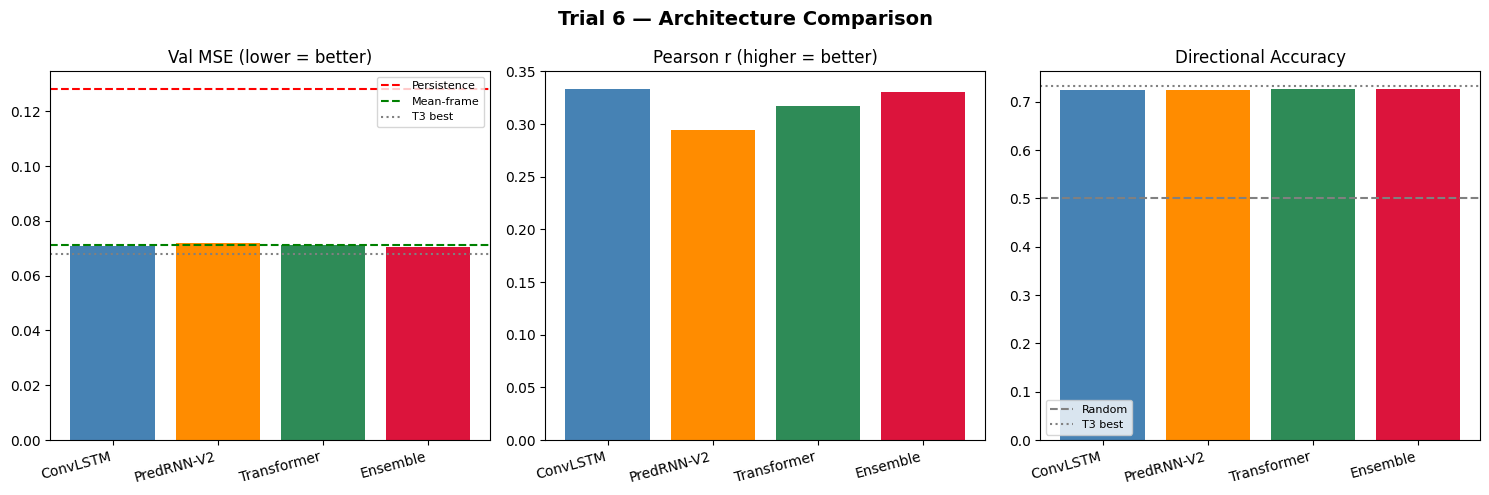

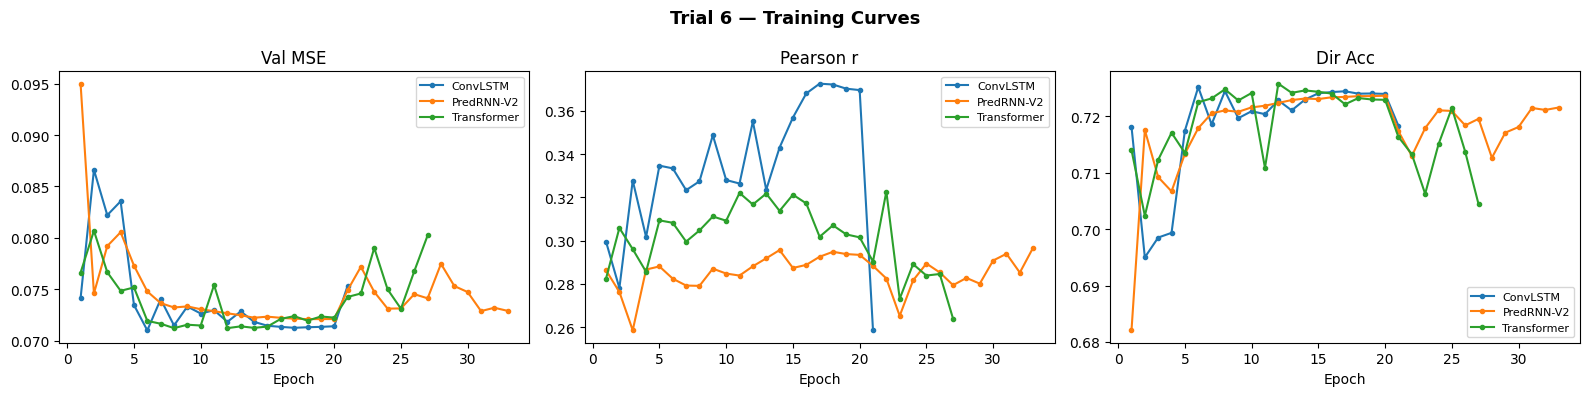


All done. Outputs saved to outputs/plots/ and outputs/predictions/


In [14]:
# Cell 14 – Full Evaluation & Comparison

val_futures = corr_video[val_snaps + HORIZON].astype(np.float32)

preds_dict = {
    'ConvLSTM'       : np.load(os.path.join(PREDS_DIR, 'trial6_convlstm_val_preds.npy')),
    'PredRNN-V2'     : np.load(os.path.join(PREDS_DIR, 'trial6_predrnn_val_preds.npy')),
    'Transformer'    : np.load(os.path.join(PREDS_DIR, 'trial6_transformer_val_preds.npy')),
    'Ensemble'       : np.load(os.path.join(PREDS_DIR, 'trial6_ensemble_val_preds.npy')),
}

results = {name: compute_metrics(p, val_futures, val_currents)
           for name, p in preds_dict.items()}
results['Persistence'] = dict(mse=persistence_mse, pearson_r=float('nan'),
                               dir_acc=0.5, vs_persist=0.0,
                               vs_mean=(mean_frame_mse - persistence_mse) / mean_frame_mse * 100)
results['Mean-frame']  = dict(mse=mean_frame_mse, pearson_r=float('nan'),
                               dir_acc=float('nan'),
                               vs_persist=(persistence_mse - mean_frame_mse) / persistence_mse * 100,
                               vs_mean=0.0)

prior_ref = {
    'T5 CNN+LSTM' : dict(mse=0.069239, pearson_r=0.3569, dir_acc=0.729),
    'T5 ConvLSTM' : dict(mse=0.068600, pearson_r=0.3724, dir_acc=0.730),
    'T5 Ensemble' : dict(mse=0.068568, pearson_r=0.3726, dir_acc=0.731),
    'T3 Best (CNN+LSTM)' : dict(mse=0.068051, pearson_r=0.3868, dir_acc=0.732),
}

print(f'{"Model":<18} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9} {"vs Pers":>9} {"vs Mean":>9}')
print('-' * 67)
for name, m in results.items():
    r  = f"{m['pearson_r']:.4f}" if not np.isnan(m['pearson_r']) else '   n/a'
    da = f"{m['dir_acc']:.3f}"   if m['dir_acc'] is not None and not np.isnan(m['dir_acc']) else '   n/a'
    print(f"{name:<18} {m['mse']:>10.6f} {r:>10} {da:>9} "
          f"{m['vs_persist']:>+8.1f}% {m['vs_mean']:>+8.1f}%")

print('\n--- Prior Trial Reference ---')
print(f'{"Model":<24} {"Val MSE":>10} {"Pearson r":>10} {"Dir Acc":>9}')
print('-' * 53)
for name, m in prior_ref.items():
    print(f"{name:<24} {m['mse']:>10.6f} {m['pearson_r']:>10.4f} {m['dir_acc']:>9.3f}")

# ── Plots ──────────────────────────────────────────────────────────────────────
t6_names   = list(preds_dict.keys())
t6_mse     = [results[n]['mse']       for n in t6_names]
t6_pearson = [results[n]['pearson_r'] for n in t6_names]
t6_dir     = [results[n]['dir_acc']   for n in t6_names]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Trial 6 — Architecture Comparison', fontsize=14, fontweight='bold')
x = np.arange(len(t6_names))

axes[0].bar(x, t6_mse, color=['steelblue','darkorange','seagreen','crimson'])
axes[0].axhline(persistence_mse, color='red',   linestyle='--', label='Persistence')
axes[0].axhline(mean_frame_mse,  color='green', linestyle='--', label='Mean-frame')
axes[0].axhline(0.068051, color='gray', linestyle=':', label='T3 best')
axes[0].set_xticks(x); axes[0].set_xticklabels(t6_names, rotation=15, ha='right')
axes[0].set_title('Val MSE (lower = better)'); axes[0].legend(fontsize=8)

axes[1].bar(x, t6_pearson, color=['steelblue','darkorange','seagreen','crimson'])
axes[1].set_xticks(x); axes[1].set_xticklabels(t6_names, rotation=15, ha='right')
axes[1].set_title('Pearson r (higher = better)')

axes[2].bar(x, t6_dir, color=['steelblue','darkorange','seagreen','crimson'])
axes[2].axhline(0.5, color='grey', linestyle='--', label='Random')
axes[2].axhline(0.732, color='gray', linestyle=':', label='T3 best')
axes[2].set_xticks(x); axes[2].set_xticklabels(t6_names, rotation=15, ha='right')
axes[2].set_title('Directional Accuracy'); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial6_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

# Training curves
hist_dict = {'ConvLSTM': hist_convlstm, 'PredRNN-V2': hist_predrnn, 'Transformer': hist_tx}
fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4))
fig2.suptitle('Trial 6 — Training Curves', fontsize=13, fontweight='bold')
for ax, (key, label) in zip(axes2, [('va_mse','Val MSE'),('pearson_r','Pearson r'),('dir_acc','Dir Acc')]):
    for name, hist in hist_dict.items():
        vals = [h[key] for h in hist if h[key] is not None]
        ax.plot(range(1, len(vals)+1), vals, label=name, marker='o', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_title(label); ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, 'trial6_training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

print('\nAll done. Outputs saved to outputs/plots/ and outputs/predictions/')
